# Demo: orquestador multi-agente sobre normativa del BCRA

**Pre-entrega 6 · Curso AI Engineering - CoderHouse** · Juan Sebastián Perez - Comisión 102130

Este notebook muestra el **flujo de delegación** del orquestador:

1. El **Supervisor** recibe el pedido y decide quién interviene (salida estructurada → `Literal`).
2. El **Investigador** busca en la normativa del BCRA (Pinecone + BM25, herramientas `buscar_normativa` / `leer_punto`).
3. El **Analista** calcula con herramientas determinísticas (`simular_prestamo`, `convertir_tasa`, `calcular_cft_flujos`).
4. El Supervisor **valida con su rúbrica** y decide si refinar o cerrar.
5. La **Síntesis** redacta la respuesta final con las contribuciones.

Las salidas quedaron guardadas al ejecutar el notebook. Si se vuelve a correr, las palabras y la cantidad de
llamadas pueden variar (el LLM no es determinístico), pero las cifras salen de herramientas y no deberían cambiar.

In [1]:
import logging
import warnings

from IPython.display import Image, Markdown, display

from graph import CONSULTA_DEMO, construir_grafo, ejecutar
from llm import crear_modelo, nombre_modelo

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.ERROR)

modelo = crear_modelo()
grafo = construir_grafo(modelo)
print(f"Modelo: {nombre_modelo(modelo)}")

Modelo: gpt-6-luna


## 1. El grafo

Líneas punteadas = aristas condicionales del supervisor. Los especialistas siempre devuelven el control al supervisor.

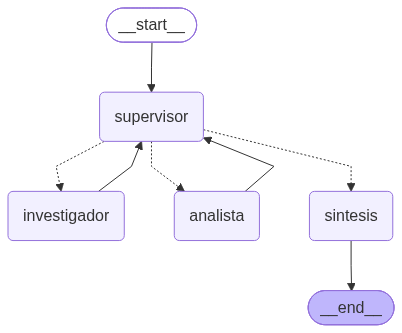

In [2]:
try:
    display(Image(grafo.get_graph().draw_mermaid_png()))
except Exception as e:  # draw_mermaid_png usa un servicio web: si no hay red, mostramos el código Mermaid
    print(f"(sin imagen: {e})\n")
    print(grafo.get_graph().draw_mermaid())

## 2. Caso principal: normativa + cálculo + síntesis

El pedido necesita **dos especialidades**: qué dice la norma sobre el CFT (Investigador) y cuánto da (Analista).
La traza muestra cada decisión del supervisor con su motivo, la instrucción que le da a cada especialista,
las herramientas que usó cada uno y la respuesta final.

In [3]:
final = await ejecutar(grafo, CONSULTA_DEMO)

USUARIO: "Me ofrecen un préstamo personal de $1.000.000 a 12 cuotas mensuales con TNA del 60%, una comisión de otorgamiento del 3% y un seguro de vida obligatorio de $2.000 por cuota. Soy consumidor final. ¿Qué conceptos tienen que incluir en el CFT según el BCRA, cuánto me da el CFT y cómo me lo tienen que informar?"



[supervisor · ronda 1] → INVESTIGADOR  (Primero hace falta establecer, con fuente normativa, qué cargos integrarían el CFT y cómo debe informarse, para que luego el analista calcule el concepto correcto.)
    instrucción: Averiguá en la normativa vigente del BCRA aplicable a préstamos personales a consumidores finales: (1) qué conceptos deben incluirse en el Costo Financiero Total (CFT), en particular si corresponden la comisión de otorgamiento y el seguro de vida obligatorio; y (2) cómo y en qué forma debe informarse el CFT al usuario. Citá cada conclusión con doc_id y punto exacto. No hagas cálculos.



[investigador] herramientas: buscar_normativa, leer_punto, buscar_normativa, buscar_normativa, buscar_normativa, leer_punto, leer_punto, leer_punto, leer_punto, buscar_normativa
    HALLAZGOS:
    - El CFT se determina agregando a la tasa de interés el efecto de las comisiones y cargos asociados a la operación, cualquiera sea su concepto. Por ese criterio general, una **comisión de otorgamiento** debe integrarse si está asociada al préstamo y se cobra al prestatario; la norma no la enumera por separado. El CFT se expresa como tasa efectiva anual y en porcentaje con al menos un de...



[supervisor · ronda 2] → ANALISTA  (El investigador ya aportó el fundamento normativo y ahora hace falta el cálculo del CFT con herramienta, respetando los conceptos computables señalados.)
    instrucción: Calculá el CFT del préstamo personal con estos datos del usuario: capital de $1.000.000; 12 cuotas mensuales; TNA 60%; comisión de otorgamiento del 3%; seguro de vida obligatorio de $2.000 por cuota; prestatario consumidor final. La normativa relevada por el investigador indica incluir las comisiones y cargos asociados al préstamo, el seguro obligatorio exigido como condición para obtenerlo y el IVA sobre intereses cuando el prestatario es consumidor final (t-tasint, 3.4.1 y 3.4.2.3–3.4.2.7). Usá una herramienta de cálculo. No agregues supuestos técnicos propios; si no se puede obtener un CFT único con los datos disponibles, informá exactamente qué datos faltan y, si tu herramienta usa valores por defecto, identificá cuáles.



[analista] herramientas: simular_prestamo
    RESULTADOS:
    - **CFT: 123,88% TEA**.
    - **TEA de la tasa pactada: 79,62%**.
    - **Desembolso neto recibido:** $970.000,00.
    - **Cuota pura:** $112.389,99. La primera cuota total es $124.746,15 y la última, $115.499,22.
    - **Total pagado:** $1.445.902,65.
    - Desglose acumulado del CFT: solo intereses, 79,62%; con comisión de otorgamiento, 91,27%; con seguro, 98,41%; con IVA sobre intereses, **123,88%**.
    
    ...



[supervisor · ronda 3] → ANALISTA  (Hay supuestos de cálculo no justificados como valores por defecto ni respaldados por la información disponible, así que corresponde validar o corregir el cálculo antes de sintetizar.)
    instrucción: Refiná el cálculo del préstamo personal: capital $1.000.000, 12 cuotas mensuales, TNA 60%, comisión de otorgamiento 3%, seguro obligatorio de $2.000 por cuota y consumidor final. La norma relevada exige incluir comisión/cargos asociados, seguro obligatorio e IVA sobre intereses (t-tasint, 3.4.1 y 3.4.2.3–3.4.2.7). Usá simular_prestamo. No supongas sistema de amortización ni momento de cobro de la comisión salvo que sean valores por defecto documentados de la herramienta; identificá todos los valores por defecto efectivamente usados, incluido el tratamiento del IVA. Si no se obtiene un CFT único, informá exactamente qué datos faltan y no presentes un resultado como único.



[analista] herramientas: simular_prestamo
    RESULTADOS:
    - **CFT: 123,88% TEA.**
    - **TEA de la tasa pactada: 79,62%.**
    - **Cuota pura:** $112.389,99.
    - **Primera cuota total:** $124.746,15; **última cuota total:** $115.499,22.
    - **Desembolso neto:** $970.000,00; **total pagado:** $1.445.902,65.
    - Desglose acumulado del CFT: solo intereses, **79,62%**; más comisión, **91,27%**; más seguro, **98,41%**; más IVA sobre intereses, **123,88%**.
    - T...



[supervisor · ronda 4] → SINTESIS  (Las contribuciones cubren las tres partes del pedido y cumplen los requisitos de fuentes, cálculo con herramienta, coherencia normativa y explicitación de los valores por defecto.)




[sintesis] RESPUESTA FINAL:
## Qué debe incluirse en el CFT

- **La comisión de otorgamiento** debe computarse si está asociada al préstamo y se cobra al prestatario: el criterio general es sumar a la tasa de interés el efecto de las comisiones y cargos asociados a la operación, cualquiera sea su concepto. La norma no menciona esa comisión específicamente por nombre. (**t-tasint, 3.4.1**)
- **El seguro de vida obligatorio** debe incluirse si contratarlo es condición para obtener el crédito. La norma incluye las primas y demás erogaciones por seguros vinculados con los prestatarios cuando se exige esa condición. (**t-tasint, 3.4.2.3–3.4.2.7**)
- Como sos **consumidor final**, también se incluye el **IVA sobre los intereses**. En cambio, los impuestos nacionales, provinciales y municipales que graven préstamos personales no se computan en el CFT. (**t-tasint, 3.4.2.3–3.4.2.7 y 3.4.3.2**)

## Cálculo para la oferta

Con los datos indicados y usando los valores por defecto documentados de

### 2.1 Estado compartido: quién decidió qué y quién aportó qué

El estado (`state.py`) acumula `decisiones` del supervisor y `contribuciones` de los especialistas
(reducer `operator.add`). Es lo que evita la pérdida de contexto entre agentes: cada aporte queda atribuido.

In [4]:
def tabla(filas, columnas):
    def celda(v):
        return str(v).replace("|", "\\|").replace("\n", " ")
    lineas = ["| " + " | ".join(columnas) + " |", "|" + "---|" * len(columnas)]
    lineas += ["| " + " | ".join(celda(f.get(c, "")) for c in columnas) + " |" for f in filas]
    return Markdown("\n".join(lineas))

display(Markdown("**Decisiones del supervisor**"))
display(tabla(final["decisiones"], ["ronda", "destino", "motivo"]))

resumen = [{**c, "herramientas": ", ".join(c["herramientas"]), "resultado": c["resultado"][:220] + "..."}
           for c in final["contribuciones"]]
display(Markdown("**Contribuciones de los especialistas**"))
display(tabla(resumen, ["ronda", "agente", "herramientas", "resultado"]))

print(f"delegaciones: {final['delegaciones']} | tarea_completa: {final['tarea_completa']}")

**Decisiones del supervisor**

| ronda | destino | motivo |
|---|---|---|
| 1 | investigador | Primero hace falta establecer, con fuente normativa, qué cargos integrarían el CFT y cómo debe informarse, para que luego el analista calcule el concepto correcto. |
| 2 | analista | El investigador ya aportó el fundamento normativo y ahora hace falta el cálculo del CFT con herramienta, respetando los conceptos computables señalados. |
| 3 | analista | Hay supuestos de cálculo no justificados como valores por defecto ni respaldados por la información disponible, así que corresponde validar o corregir el cálculo antes de sintetizar. |
| 4 | sintesis | Las contribuciones cubren las tres partes del pedido y cumplen los requisitos de fuentes, cálculo con herramienta, coherencia normativa y explicitación de los valores por defecto. |

**Contribuciones de los especialistas**

| ronda | agente | herramientas | resultado |
|---|---|---|---|
| 1 | investigador | buscar_normativa, leer_punto, buscar_normativa, buscar_normativa, buscar_normativa, leer_punto, leer_punto, leer_punto, leer_punto, buscar_normativa | HALLAZGOS: - El CFT se determina agregando a la tasa de interés el efecto de las comisiones y cargos asociados a la operación, cualquiera sea su concepto. Por ese criterio general, una **comisión de otorgamiento** debe i... |
| 2 | analista | simular_prestamo | RESULTADOS: - **CFT: 123,88% TEA**. - **TEA de la tasa pactada: 79,62%**. - **Desembolso neto recibido:** $970.000,00. - **Cuota pura:** $112.389,99. La primera cuota total es $124.746,15 y la última, $115.499,22. - **To... |
| 3 | analista | simular_prestamo | RESULTADOS: - **CFT: 123,88% TEA.** - **TEA de la tasa pactada: 79,62%.** - **Cuota pura:** $112.389,99. - **Primera cuota total:** $124.746,15; **última cuota total:** $115.499,22. - **Desembolso neto:** $970.000,00; **... |

delegaciones: 3 | tarea_completa: True


### 2.2 Verificación de la cifra

El CFT de la respuesta tiene que coincidir con el que calcula la herramienta del analista de forma directa
(sin LLM). Así se comprueba que la síntesis copió la cifra y no la reescribió.

In [5]:
from tools.finanzas import simular

esperado = simular(1_000_000, 60, 12, comision_otorgamiento_pct=3, seguro_por_cuota=2000,
                   iva_sobre_intereses_pct=21)["cft_pct"]
cft_texto = f"{esperado:.2f}".replace(".", ",")
respuesta = final["messages"][-1].text
print(f"CFT calculado directamente: {cft_texto}%")
print(f"¿Aparece en la respuesta final? {'SÍ' if cft_texto in respuesta else 'NO'}")

CFT calculado directamente: 123,88%
¿Aparece en la respuesta final? SÍ


## 3. Casos borde

**3.1 Pregunta ajena al dominio**: el supervisor va directo a síntesis, sin gastar delegaciones.

In [6]:
borde_1 = await ejecutar(grafo, "¿Cómo está el clima en Buenos Aires?")
print(f"delegaciones: {borde_1['delegaciones']}")

USUARIO: "¿Cómo está el clima en Buenos Aires?"



[supervisor · ronda 1] → SINTESIS  (Es una pregunta ajena a la normativa del BCRA, por lo que corresponde responderla directamente.)




[sintesis] RESPUESTA FINAL:
Soy asistente de consultas sobre normativa del BCRA. Puedo ayudarte con temas de protección de usuarios, cuentas y depósitos, tasas y crédito, y efectivo mínimo. No puedo informar el clima actual de Buenos Aires.

delegaciones: 0


**3.2 Faltan datos imprescindibles**: el analista informa qué falta (no inventa capital ni tasa) y el
supervisor cierra sin insistir. Es la condición de parada por "suficiencia" del lado negativo: no hay más
que hacer con lo que dio el usuario.

In [7]:
borde_2 = await ejecutar(grafo, "¿Cuánto me da el CFT de un préstamo a 12 cuotas con una comisión de otorgamiento del 3%?")
print(f"delegaciones: {borde_2['delegaciones']}")

USUARIO: "¿Cuánto me da el CFT de un préstamo a 12 cuotas con una comisión de otorgamiento del 3%?"



[supervisor · ronda 1] → INVESTIGADOR  (Primero hace falta establecer normativamente si la comisión integra el CFT; después se podrá evaluar qué datos faltan para calcularlo.)
    instrucción: Averiguá en la normativa del BCRA aplicable al Costo Financiero Total de préstamos si una comisión de otorgamiento debe incluirse en el CFT y cómo se trata. Indicá la fuente con doc_id y punto. No hagas cálculos.



[investigador] herramientas: buscar_normativa, leer_punto
    HALLAZGOS:
    - La comisión de otorgamiento debe incluirse en el CFT si está asociada a la operación: la norma dispone que el CFT se determina agregando a la tasa de interés el efecto de las comisiones y cargos asociados, cualquiera sea su concepto.
    - La comisión de otorgamiento no aparece mencionada por separado en la lista de conceptos computables; su inclusión se desprende de la regla general. El ...



[supervisor · ronda 2] → ANALISTA  (La comisión debe incluirse en el CFT, pero hace falta determinar si los datos provistos bastan para calcularlo y, en su defecto, precisar qué información falta.)
    instrucción: Determiná si puede calcularse el CFT de un préstamo con los datos disponibles: 12 cuotas y comisión de otorgamiento del 3%. La comisión asociada debe computarse en el CFT, según t-tasint, punto 3.4.1. No supongas importes, fechas, tasa, sistema de amortización ni base o momento de cobro de la comisión; si faltan datos, informá cuáles hacen falta y no inventes valores.



[analista] herramientas: simular_prestamo
    RESULTADOS: No puede calcularse el CFT con los datos disponibles. La comisión asociada debe incluirse en el CFT, pero no es posible determinar su importe ni construir los flujos completos del préstamo.
    
    CÁLCULO: Se intentó usar `simular_prestamo`, pero la herramienta rechazó la entrada de prueba por falta de capital válido. Esa entrada no representa los datos del caso y no se usó para obtener un C...



[supervisor · ronda 3] → SINTESIS  (Las contribuciones cubren el pedido y explican por qué no se puede dar un CFT sin inventar datos.)




[sintesis] RESPUESTA FINAL:
Con los datos disponibles no se puede calcular el CFT. Saber que el préstamo tiene 12 cuotas y una comisión de otorgamiento del 3% no alcanza para determinar los flujos del préstamo.

La comisión debe incluirse en el CFT si está asociada a la operación. Para calcularlo faltan: el capital, la tasa de interés, las fechas o periodicidad de los pagos, el sistema de amortización o el detalle de los flujos, y la base y el momento de cobro de la comisión.

La normativa dispone que el CFT se determine agregando a la tasa de interés el efecto de las comisiones y cargos asociados, y que se exprese como tasa efectiva anual. **Fuente: t-tasint, punto 3.4.1.**

delegaciones: 2


## 4. Resumen

| Requisito de la consigna | Dónde se ve en esta demo |
|---|---|
| Topología jerárquica con Supervisor como router | Sección 1 (grafo) y las líneas `[supervisor · ronda N] → ...` |
| ≥ 2 especialistas con herramientas acotadas | `[investigador] herramientas: buscar_normativa, leer_punto...` / `[analista] herramientas: simular_prestamo` |
| Estado compartido estructurado | Sección 2.1: `decisiones` y `contribuciones` atribuidas por agente y ronda |
| Supervisor decide si refinar o finalizar | Motivos de cada decisión (rúbrica de 5 criterios en `agents/supervisor.py`) |
| Fase de síntesis final | `[sintesis] RESPUESTA FINAL` |
| Condición de parada | Casos borde (0 y 1 delegación) + `MAX_DELEGACIONES = 5` |